# Week 10 — Relationships & Modeling (hands-on)

**Course:** DATS 2102 · Data Visualization for Data Science

**Dataset:** home sales in Ames, Iowa (1,460 homes). The Plotly section at the
end uses the diabetes dataset that ships with scikit-learn.

> We do not use Boston Housing here. The ethics case notebook from this week
> explains why.

## Environment setup

In [1]:
# Imports
from pathlib import Path

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm

sns.set_theme()

In [2]:
# Load the Ames data: from the data/ folder if you have it, otherwise from the course site
local = Path("data/ames.csv")
URL = "https://www.junjunyin.com/datascience/dats2102/weekly/week10/data/ames.csv"
df = pd.read_csv(local if local.exists() else URL)

# Quick peek
df.head()

,GrLivArea,SalePrice,YearBuilt,HouseStyle,OverallQual,TotalBsmtSF,GarageArea,LotArea,Neighborhood,CentralAir,YrSold
0,1710,208500,2003,2Story,7,856,548,8450,CollgCr,Y,2008
1,1262,181500,1976,1Story,6,1262,460,9600,Veenker,Y,2007
2,1786,223500,2001,2Story,7,920,608,11250,CollgCr,Y,2008
3,1717,140000,1915,2Story,7,756,642,9550,Crawfor,Y,2006
4,2198,250000,2000,2Story,8,1145,836,14260,NoRidge,Y,2008


### Variables (subset)

- **SalePrice**: sale price of the home, in dollars
- **GrLivArea**: above-ground living area, in square feet
- **YearBuilt**: year the home was built
- **HouseStyle**: `1Story`, `2Story`, and others
- **OverallQual**: overall material and finish quality, 1 to 10
- **TotalBsmtSF**, **GarageArea**, **LotArea**: basement, garage and lot size, in square feet

## scatterplot

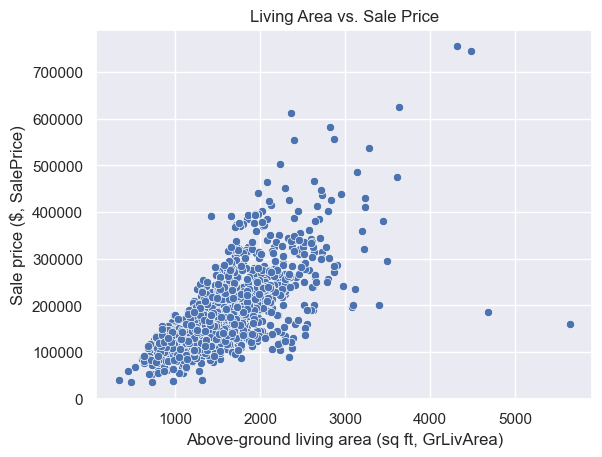

In [3]:
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice")
plt.title("Living Area vs. Sale Price")
plt.xlabel("Above-ground living area (sq ft, GrLivArea)")
plt.ylabel("Sale price ($, SalePrice)")
plt.show()

## Basic scatter + marginal histograms
`jointplot` combines a **bivariate plot** in the center (joint) with **marginal distributions** along axes.

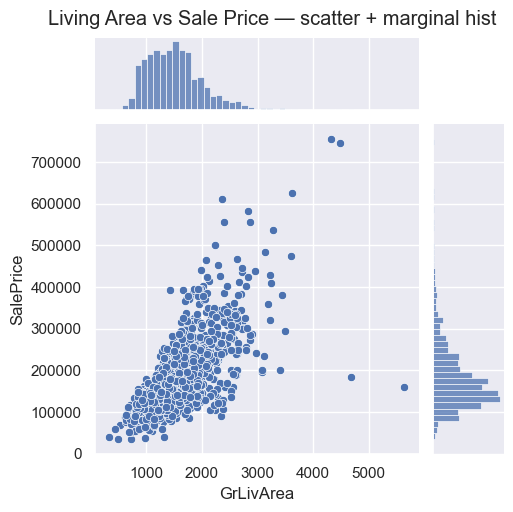

In [4]:
g = sns.jointplot(
    data=df, x="GrLivArea", y="SalePrice",
    kind="scatter", height=5, ratio=4, space=0.2
)
g.fig.suptitle("Living Area vs Sale Price — scatter + marginal hist", y=1.02)
plt.show()

## Scatterplot with regression line (living area vs. price)

In [5]:
# Your turn: draw the same scatter with a fitted line, using sns.regplot.
# Fill in data, x and y. The next cell shows one answer.
# sns.regplot()

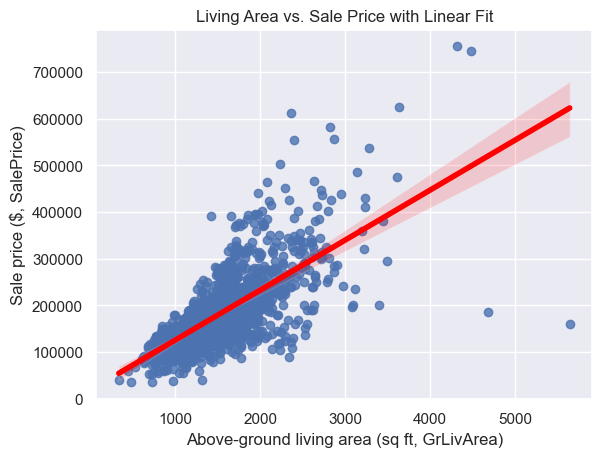

In [6]:
sns.regplot(data=df, x="GrLivArea", y="SalePrice", line_kws={"color": "red", "linewidth": 4})
plt.title("Living Area vs. Sale Price with Linear Fit")
plt.xlabel("Above-ground living area (sq ft, GrLivArea)")
plt.ylabel("Sale price ($, SalePrice)")
plt.show()

## Scatter with regression line (and 95% CI)

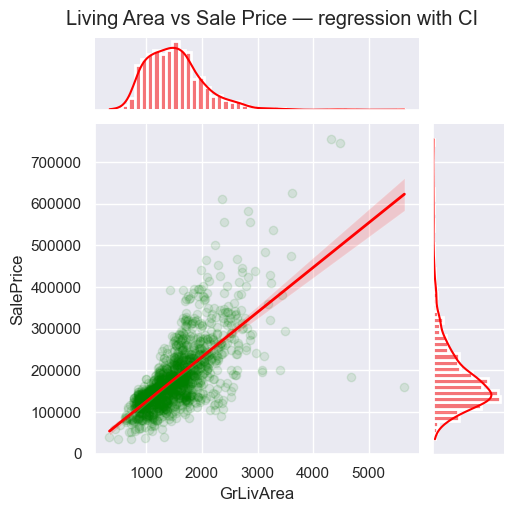

In [7]:
g = sns.jointplot(
    data=df, x="GrLivArea", y="SalePrice",
    kind="reg", height=5, ratio=4, space=0.2,
    # joint_kws={"line_kws": {"linewidth":5, "color": "red"}, "scatter_kws": {"alpha":0.6}, 'ci': 80}
    joint_kws={"line_kws": {"linewidth":2, "color": "red"}, "scatter_kws": {"alpha":0.1, "color":"green"}, 'ci': 80,},
    marginal_kws={"linewidth": 2, "color": "red"}

    # joint_kws={"line_kws": {"linewidth":2}, "scatter_kws": {"alpha":0.6}, 'ci': 95}
)
g.fig.suptitle("Living Area vs Sale Price — regression with CI", y=1.02)
plt.show()

## Multivariate visualization using hue/facet
`HouseStyle` records the style of the home. We keep the two most common, `1Story` and `2Story`, and fit one line for each.

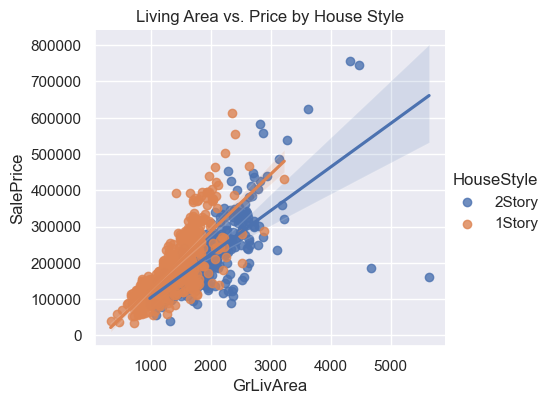

In [8]:
two = df[df["HouseStyle"].isin(["1Story", "2Story"])]

sns.lmplot(data=two, x="GrLivArea", y="SalePrice", hue="HouseStyle", height=4, aspect=1.2)
plt.title("Living Area vs. Price by House Style")
plt.show()

## Correlation matrix heatmap

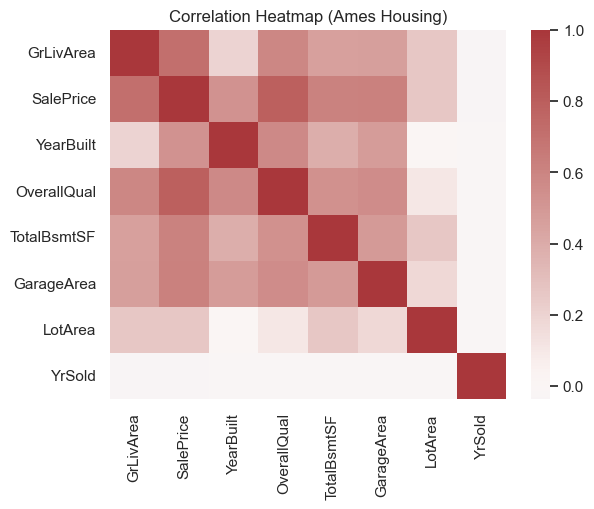

In [9]:
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=False, cmap="vlag", center=0)
plt.title("Correlation Heatmap (Ames Housing)")
plt.show()

## OLS: SalePrice ~ GrLivArea

In [10]:
X = sm.add_constant(df["GrLivArea"])
y = df["SalePrice"]
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.502
Model:                            OLS   Adj. R-squared:                  0.502
Method:                 Least Squares   F-statistic:                     1471.
Date:                Thu, 12 Nov 2026   Prob (F-statistic):          4.52e-223
Time:                        15:21:42   Log-Likelihood:                -18035.
No. Observations:                1460   AIC:                         3.607e+04
Df Residuals:                    1458   BIC:                         3.608e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.857e+04   4480.755      4.144      0.0

In [11]:
X = sm.add_constant(df[["GrLivArea", "OverallQual", "YearBuilt"]])
y = df["SalePrice"]
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.737
Model:                            OLS   Adj. R-squared:                  0.737
Method:                 Least Squares   F-statistic:                     1363.
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:21:42   Log-Likelihood:                -17568.
No. Observations:                1460   AIC:                         3.514e+04
Df Residuals:                    1456   BIC:                         3.517e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const       -1.053e+06   8.38e+04    -12.567      

## Residuals diagnostics

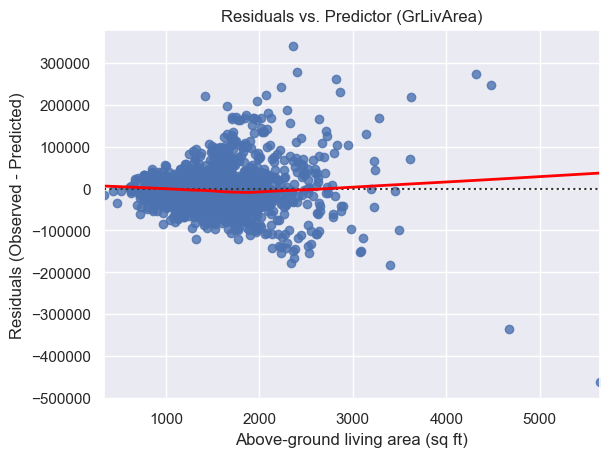

In [12]:
# sns.residplot(x=df["GrLivArea"], y=df["SalePrice"], lowess=True)
sns.residplot(x=df["GrLivArea"], y=df["SalePrice"], lowess=True, line_kws={"linewidth":2, "color": "red"})
plt.title("Residuals vs. Predictor (GrLivArea)")
plt.xlabel("Above-ground living area (sq ft)")
plt.ylabel("Residuals (Observed - Predicted)")
plt.show()

## Predicted vs Actual

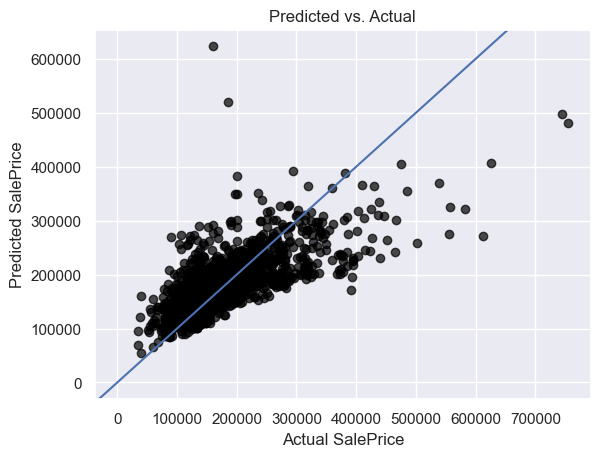

In [13]:
X = sm.add_constant(df["GrLivArea"])
y = df["SalePrice"]
model = sm.OLS(y, X).fit()
pred = model.predict(X)

plt.figure()
plt.scatter(y, pred, alpha=0.7, color="black")
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("Predicted vs. Actual")
plt.axline((0,0), slope=1)
# plt.axline((0,0), slope=1, color = 'red')
plt.show()

## Nonlinear relationship example (quadratic)
Price does not rise in a straight line with the year a home was built, so we fit a curve (`order=2`).

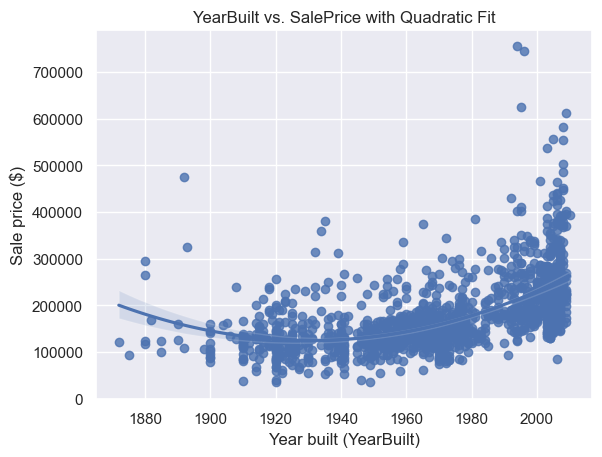

In [14]:
sns.regplot(data=df, x="YearBuilt", y="SalePrice", order=2)
plt.title("YearBuilt vs. SalePrice with Quadratic Fit")
plt.xlabel("Year built (YearBuilt)")
plt.ylabel("Sale price ($)")
plt.show()

## Q–Q plot (normality of residuals)

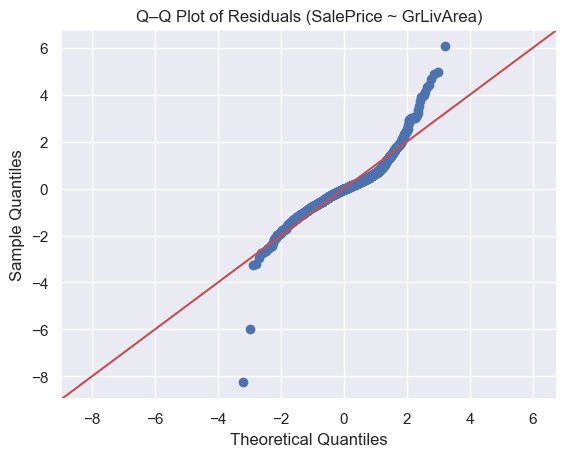

In [15]:
fitted_vals = model.fittedvalues
residuals = model.resid

sm.qqplot(residuals, line="45", fit=True)
plt.title("Q–Q Plot of Residuals (SalePrice ~ GrLivArea)")
plt.show()

## Residual histogram (shape/symmetry)

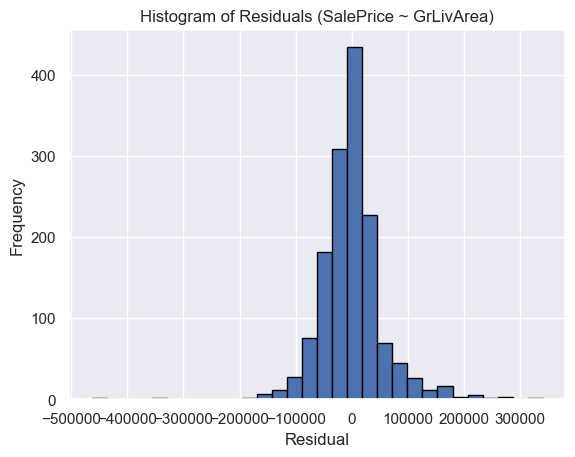

In [16]:
plt.hist(residuals, bins=30, edgecolor="black")
plt.title("Histogram of Residuals (SalePrice ~ GrLivArea)")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.show()

## Heteroscedasticity

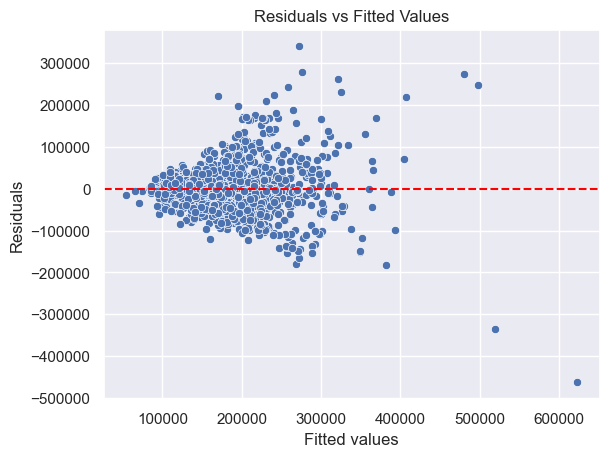

In [17]:
sns.scatterplot(x=fitted_vals, y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.title("Residuals vs Fitted Values")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.show()

## Locally Weighted Scatterplot Smoothing (LOWESS) guide line on residuals vs. fitted

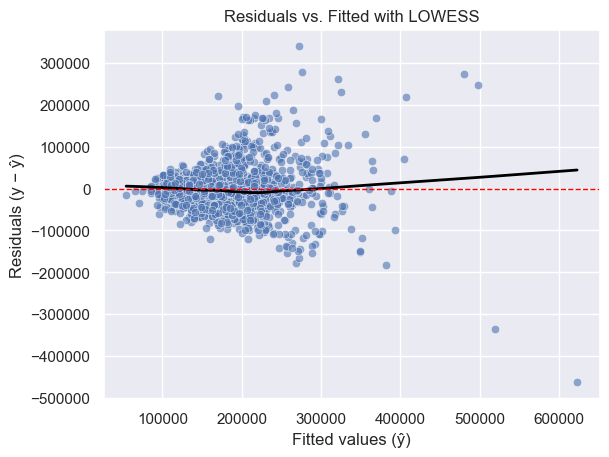

In [18]:
from statsmodels.nonparametric.smoothers_lowess import lowess

sns.scatterplot(x=fitted_vals, y=residuals, alpha=0.6)
lo = lowess(residuals, fitted_vals, frac=0.6)
plt.plot(lo[:,0], lo[:,1], color="black", linewidth=2)
plt.axhline(0, color="red", linestyle="--", linewidth=1)
plt.title("Residuals vs. Fitted with LOWESS")
plt.xlabel("Fitted values (ŷ)")
plt.ylabel("Residuals (y − ŷ)")
plt.show()

## The same charts in Altair
Altair builds a chart from a data frame and a description of the encodings. Hover over a point to see its values; scroll to zoom.

In [19]:
import altair as alt

alt.renderers.enable('default')  # Jupyter

RendererRegistry.enable('default')

In [20]:
# Altair stores the data inside the chart, so pass only the columns we use
ames = df[["GrLivArea", "SalePrice", "HouseStyle", "YearBuilt"]]

# 1) Define base scatter plot
base = alt.Chart(ames).mark_circle(opacity=0.6).encode(
    x=alt.X('GrLivArea:Q', title='Above-ground living area (sq ft)'),
    y=alt.Y('SalePrice:Q', title='Sale price ($)'),
    tooltip=['GrLivArea', 'SalePrice']
)

# Add regression line using transform_regression
reg = base.transform_regression('GrLivArea', 'SalePrice').mark_line(color='red')

# Combine and display
(base + reg).properties(
    title='Altair: Living Area vs Sale Price with Regression'
).interactive()

alt.LayerChart(...)

In [21]:
# 2) Faceted comparisons by house style
two_styles = ames[ames["HouseStyle"].isin(["1Story", "2Story"])]

facet_plot = alt.Chart(two_styles).mark_circle(opacity=0.6).encode(
    x=alt.X('GrLivArea:Q', title='Above-ground living area (sq ft)'),
    y=alt.Y('SalePrice:Q', title='Sale price ($)'),
    color=alt.Color('HouseStyle:N', title='House style'),
    tooltip=['GrLivArea', 'SalePrice', 'HouseStyle']
).properties(
    title='Altair: Living Area vs Price by House Style'
).facet(column='HouseStyle:N')

facet_plot.interactive()

alt.FacetChart(...)

In [22]:
# 3) Quadratic fit
base2 = alt.Chart(ames).mark_point(opacity=0.6).encode(
    x=alt.X('YearBuilt:Q', title='Year built', scale=alt.Scale(zero=False)),
    y=alt.Y('SalePrice:Q', title='Sale price ($)'),
    tooltip=['YearBuilt', 'SalePrice']
)

quad = base2.transform_regression(
    'YearBuilt', 'SalePrice', method='poly', order=2
).mark_line(color='red')

(base2 + quad).properties(title='Altair: Quadratic Fit (YearBuilt vs SalePrice)').interactive()

alt.LayerChart(...)

## Plotly, on a second dataset
The diabetes dataset has 442 patients. `target` is a measure of disease progression one year later; `bmi`, `bp` and `s1`–`s6` are body mass index, blood pressure and six blood measurements, already centered and scaled.

In [23]:
from sklearn.datasets import load_diabetes

In [24]:
diab = load_diabetes()
diab_df = pd.DataFrame(diab.data, columns=diab.feature_names)
diab_df['target'] = diab.target

In [25]:
import plotly.express as px
import plotly.io as pio

# Load plotly.js from the web instead of storing a copy inside the notebook,
# which keeps the file small. In VS Code, use "vscode" here instead.
pio.renderers.default = "notebook_connected"

# 1) Scatter + trendline: bmi vs target
fig = px.scatter(
    diab_df, x='bmi', y='target', trendline='ols',
    title='Plotly: BMI vs Diabetes Target with OLS Trendline'
)
fig

In [26]:
# 2) Add color by a third variable (e.g., bp) and hover data
fig = px.scatter(
    diab_df, x='bmi', y='target', color='bp',
    hover_data=['s1','s2','s3','s4','s5','s6'],
    trendline='ols',
    title='Plotly: BMI vs Target colored by Blood Pressure (bp)'
)
fig

In [27]:
# 3) Residuals dashboard: compute and plot
X = sm.add_constant(diab_df[['bmi']])
y = diab_df['target']
m = sm.OLS(y, X).fit()
diab_df['pred_bmi'] = m.predict(X)
diab_df['resid_bmi'] = y - diab_df['pred_bmi']

# Predicted vs Actual
fig1 = px.scatter(
    diab_df, x='target', y='pred_bmi', title='Predicted vs Actual (BMI model)'
)
fig1.add_shape(type='line', x0=diab_df['target'].min(), y0=diab_df['target'].min(),
               x1=diab_df['target'].max(), y1=diab_df['target'].max())

# Residuals vs Predictor
fig2 = px.scatter(
    diab_df, x='bmi', y='resid_bmi', title='Residuals vs Predictor (bmi)'
)

# A cell only displays its last line, so show each figure explicitly
fig1.show()
fig2.show()

In [28]:
# 4) Nonlinear example: add a quadratic term
diab_df['bmi2'] = diab_df['bmi'] ** 2
X2 = sm.add_constant(diab_df[['bmi','bmi2']])
m2 = sm.OLS(y, X2).fit()
diab_df['pred_quad'] = m2.predict(X2)

fig = px.scatter(
    diab_df, x='bmi', y='target', title='Plotly: Quadratic Fit (BMI^2)'
)
fig.add_traces(px.line(diab_df.sort_values('bmi'), x='bmi', y='pred_quad').data)
fig

In [29]:
# 5) Residuals panel with a dropdown: pick the predictor, both charts update
import plotly.graph_objects as go
from plotly.subplots import make_subplots

preds = ["bmi","bp","s1","s2","s3","s4","s5","s6"]
y_np = y.to_numpy()  # y is pandas Series

def fit_one(p):
    Xp = sm.add_constant(diab_df[[p]])
    fitted_p = sm.OLS(y, Xp).fit().predict(Xp).to_numpy()
    return fitted_p, y_np - fitted_p

# Start with the first predictor: [top scatter, diagonal line, bottom scatter]
fitted0, resid0 = fit_one(preds[0])
line0 = [fitted0.min(), fitted0.max()]

fig = make_subplots(rows=2, cols=1, vertical_spacing=0.12,
                    subplot_titles=("Actual vs Fitted", "Residuals vs Fitted"))
fig.add_trace(go.Scatter(x=fitted0, y=y_np, mode="markers", name="Actual vs Fitted"), 1, 1)
fig.add_trace(go.Scatter(x=line0, y=line0, mode="lines", name="y = x", line=dict(dash="dash")), 1, 1)
fig.add_trace(go.Scatter(x=fitted0, y=resid0, mode="markers", name="Residuals"), 2, 1)

buttons = []
for p in preds:
    fitted_p, resid_p = fit_one(p)
    xline = [fitted_p.min(), fitted_p.max()]
    buttons.append(dict(
        label=p,
        method="update",
        args=[
            # Update x/y for: [top scatter, diagonal line, bottom scatter]
            {"x": [fitted_p, xline, fitted_p],
             "y": [y_np,     xline, resid_p]},
            {"title": f"Residuals Panel — OLS with predictor '{p}'"}
        ],
    ))

fig.update_xaxes(title_text="Fitted (ŷ)")
fig.update_yaxes(title_text="Actual (y)", row=1, col=1)
fig.update_yaxes(title_text="Residual (y − ŷ)", row=2, col=1)
fig.update_layout(
    height=650, title=f"Residuals Panel — OLS with predictor '{preds[0]}'",
    updatemenus=[dict(type="dropdown", x=1.02, y=1, xanchor="left",
                      buttons=buttons, showactive=True)]
)
fig

### Linked selection
Drag a box around points in either chart and the same patients are highlighted in the other. Double-click a chart to clear. This needs `ipywidgets`, and `anywidget` with Plotly 6 or newer (`pip install ipywidgets anywidget`, then restart the kernel).

In [30]:
# Interactive residuals panel with TWO-WAY linking (top <-> bottom)

import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
import statsmodels.api as sm
from sklearn.datasets import load_diabetes

# If you're in classic Jupyter or VS Code:
# pio.renderers.default = "jupyterlab"  # try "vscode" or "jupyterlab" if needed

# --- Data & model (a fresh copy, so the Ames `df` above is left alone)
diab = load_diabetes()
link_df = pd.DataFrame(diab.data, columns=diab.feature_names)
link_df["target"] = diab.target

pred = "bmi"
X = sm.add_constant(link_df[[pred]])
y = link_df["target"]
m = sm.OLS(y, X).fit()
link_df["fitted"] = m.predict(X)
link_df["resid"]  = y - link_df["fitted"]

# --- Build FigureWidget with two linked charts
base = make_subplots(
    rows=2, cols=1, shared_xaxes=False,
    subplot_titles=(f"Actual vs Fitted (predictor: {pred})", "Residuals vs Fitted"),
    vertical_spacing=0.12
)
fig = go.FigureWidget(base)
fig.update_layout(height=650, width=800, dragmode="select", title="Linked Residuals Panel")

# Top: Actual vs Fitted (selectable)
top_scatter = go.Scatter(
    x=link_df["fitted"], y=link_df["target"],
    mode="markers", name="Actual vs Fitted",
    marker=dict(size=7, opacity=0.8),
    selected=dict(marker=dict(color="crimson", size=9)),
    unselected=dict(marker=dict(opacity=0.2)),
)

diag_line = go.Scatter(
    x=[link_df["fitted"].min(), link_df["fitted"].max()],
    y=[link_df["fitted"].min(), link_df["fitted"].max()],
    mode="lines", name="y = x", line=dict(dash="dash")
)

# Bottom: Residuals vs Fitted (selectable)
bottom_scatter = go.Scatter(
    x=link_df["fitted"], y=link_df["resid"],
    mode="markers", name="Residuals",
    marker=dict(size=7, opacity=0.8),
    selected=dict(marker=dict(color="crimson", size=9)),
    unselected=dict(marker=dict(opacity=0.2)),
)

fig.add_trace(top_scatter, 1, 1)
fig.add_trace(diag_line, 1, 1)
fig.add_trace(bottom_scatter, 2, 1)

fig.update_xaxes(title_text="Fitted (ŷ)", row=1, col=1)
fig.update_yaxes(title_text="Actual (y)", row=1, col=1)
fig.update_xaxes(title_text="Fitted (ŷ)", row=2, col=1)
fig.update_yaxes(title_text="Residual (y − ŷ)", row=2, col=1)
fig.add_hline(y=0, line_dash="dash", row=2, col=1)

# --- Highlight layers: one per chart, empty until points are selected in the OTHER chart.
# Plotly keeps control of `selectedpoints` on a chart that has a selection box, so the
# linked points are drawn as their own trace instead of by setting that property.
highlight = dict(
    mode="markers", marker=dict(color="crimson", size=9),
    showlegend=False, hoverinfo="skip",
    selected=dict(marker=dict(opacity=1)), unselected=dict(marker=dict(opacity=1)),
)
fig.add_trace(go.Scatter(x=[], y=[], name="linked", **highlight), 1, 1)
fig.add_trace(go.Scatter(x=[], y=[], name="linked", **highlight), 2, 1)

# --- Two-way linking handlers
top = fig.data[0]            # top_scatter
bottom = fig.data[2]         # bottom_scatter
top_linked = fig.data[3]     # highlight layer in the top chart
bottom_linked = fig.data[4]  # highlight layer in the bottom chart

# Plotly calls EVERY trace's handler on every selection, so each handler remembers
# what it saw last and only acts when the selection in its own chart has changed.
last = {"top": (), "bottom": ()}

def link_top_to_bottom(trace, points, selector):
    # Select in TOP -> highlight the same rows in BOTTOM
    inds = tuple(points.point_inds)
    if inds == last["top"]:
        return
    last["top"] = inds
    rows = link_df.iloc[list(inds)]
    with fig.batch_update():
        bottom_linked.x, bottom_linked.y = rows["fitted"], rows["resid"]
        top_linked.x, top_linked.y = [], []

def link_bottom_to_top(trace, points, selector):
    # Select in BOTTOM -> highlight the same rows in TOP
    inds = tuple(points.point_inds)
    if inds == last["bottom"]:
        return
    last["bottom"] = inds
    rows = link_df.iloc[list(inds)]
    with fig.batch_update():
        top_linked.x, top_linked.y = rows["fitted"], rows["target"]
        bottom_linked.x, bottom_linked.y = [], []

top.on_selection(link_top_to_bottom)
bottom.on_selection(link_bottom_to_top)

# Double-click a chart to clear its selection; clear the linked highlights with it
def clear_linked(trace, points):
    last["top"], last["bottom"] = (), ()
    with fig.batch_update():
        top_linked.x, top_linked.y = [], []
        bottom_linked.x, bottom_linked.y = [], []

top.on_deselect(clear_linked)
bottom.on_deselect(clear_linked)

fig  # In Jupyter, simply put `fig` as the last line to display

FigureWidget({
    'data': [{'marker': {'opacity': 0.8, 'size': 7},
              'mode': 'markers',
              'name': 'Actual vs Fitted',
              'selected': {'marker': {'color': 'crimson', 'size': 9}},
              'type': 'scatter',
              'uid': '2a1347fa-25d8-4411-85c6-31ec137cca34',
              'unselected': {'marker': {'opacity': 0.2}},
              'x': array([210.71003806, 103.26219543, 194.33703347, ..., 137.0315174 ,
                          189.22046954,  82.79593969]),
              'xaxis': 'x',
              'y': array([151.,  75., 141., ..., 132., 220.,  57.]),
              'yaxis': 'y'},
             {'line': {'dash': 'dash'},
              'mode': 'lines',
              'name': 'y = x',
              'type': 'scatter',
              'uid': 'd592a4cb-d01a-4685-8761-d7493243c569',
              'x': [66.42293509524852, 314.06462955168723],
              'xaxis': 'x',
              'y': [66.42293509524852, 314.06462955168723],
              'yaxis'

### The same linked selection in Altair
Altair has linked selection built in. One `selection_interval()` is shared by both charts, so there are no handlers to write and no extra packages to install. Drag a box in either chart; a new box replaces the old one. With nothing selected, every point is drawn in crimson.

Because the linking runs in the browser, this chart keeps working in a rendered HTML page, which the Plotly widget above cannot do.

To read more:

- [Interactive Charts](https://altair-viz.github.io/user_guide/interactions/index.html) — how selections work in Altair
- [Parameters, Conditions, & Filters](https://altair-viz.github.io/user_guide/interactions/parameters.html) — sharing one selection between charts, as this cell does
- [Multi-panel Scatter Plot with Linked Brushing](https://altair-viz.github.io/gallery/scatter_linked_brush.html) — a gallery example close to this one

In [31]:
# One brush, shared by both charts. Drag a box in either one.
brush = alt.selection_interval()

linked = link_df[["bmi", "target", "fitted", "resid"]]

points = alt.Chart(linked).mark_circle(size=50).encode(
    color=alt.condition(brush, alt.value("crimson"), alt.value("lightgray")),
    tooltip=["bmi", "target", "fitted", "resid"],
).add_params(brush).properties(width=600, height=240)

top_chart = points.encode(
    x=alt.X("fitted:Q", title="Fitted (ŷ)"),
    y=alt.Y("target:Q", title="Actual (y)"),
).properties(title="Actual vs Fitted (predictor: bmi)")

bottom_chart = points.encode(
    x=alt.X("fitted:Q", title="Fitted (ŷ)"),
    y=alt.Y("resid:Q", title="Residual (y − ŷ)"),
).properties(title="Residuals vs Fitted")

top_chart & bottom_chart

alt.VConcatChart(...)